In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

In [2]:
from pathlib import Path

# Locate the dataset
dataset_path = Path.cwd().parent / "Datasets" / "1) iris.csv"

# Load the dataset
df = pd.read_csv(dataset_path)

# Display first five rows
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
# Check dataset information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (150, 5)

Column names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [4]:
# Separate input features and target variable

X = df.drop("species", axis=1)
y = df["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFlower species:")
print(y.unique())

Features shape: (150, 4)
Target shape: (150,)

Flower species:
<StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (120, 4)
Testing features: (30, 4)


In [6]:
# Create the Decision Tree model
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [7]:
# Predict flower species
y_pred = model.predict(X_test)

# Compare actual and predicted values
results = pd.DataFrame({
    "Actual Species": y_test.values,
    "Predicted Species": y_pred
})

print(results.head(10))

  Actual Species Predicted Species
0         setosa            setosa
1      virginica         virginica
2     versicolor        versicolor
3     versicolor        versicolor
4         setosa            setosa
5     versicolor        versicolor
6         setosa            setosa
7         setosa            setosa
8      virginica         virginica
9     versicolor        versicolor


In [8]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Display classification report
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 96.67 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


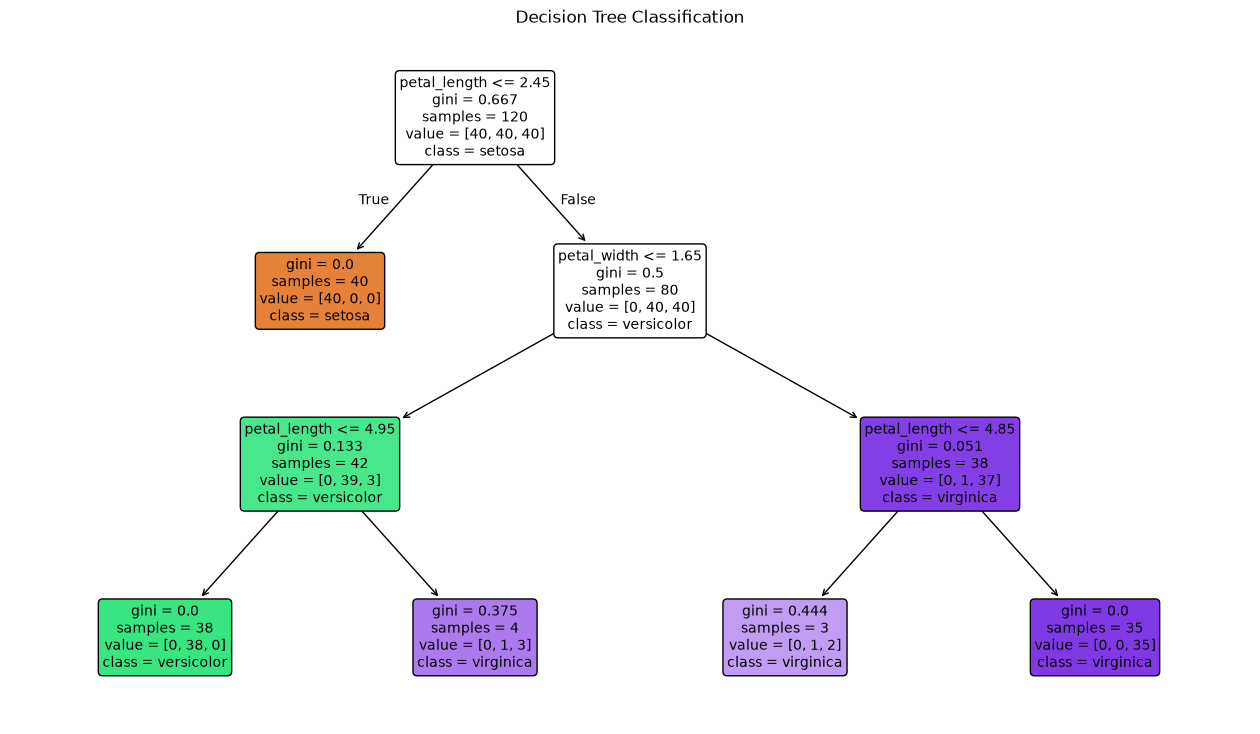

In [9]:
plt.figure(figsize=(16, 9))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Classification")
plt.show()

In [10]:
# Create an unrestricted Decision Tree
full_tree = DecisionTreeClassifier(random_state=42)

# Train the unrestricted tree
full_tree.fit(X_train, y_train)

# Make predictions
full_predictions = full_tree.predict(X_test)

# Calculate accuracy
full_accuracy = accuracy_score(y_test, full_predictions)

# Compare both models
print("Pruned Tree Accuracy:", round(accuracy * 100, 2), "%")
print("Unrestricted Tree Accuracy:", round(full_accuracy * 100, 2), "%")

print("\nPruned Tree Depth:", model.get_depth())
print("Unrestricted Tree Depth:", full_tree.get_depth())

Pruned Tree Accuracy: 96.67 %
Unrestricted Tree Accuracy: 93.33 %

Pruned Tree Depth: 3
Unrestricted Tree Depth: 5


        Feature  Importance
2  petal_length    0.579077
3   petal_width    0.420923
1   sepal_width    0.000000
0  sepal_length    0.000000


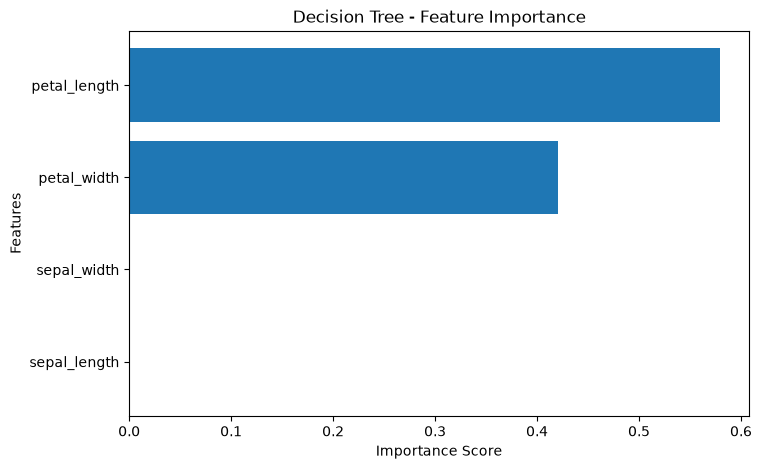

In [11]:
# Get feature importance scores
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

# Sort features by importance
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

# Visualize feature importance
plt.figure(figsize=(8, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Decision Tree - Feature Importance")
plt.gca().invert_yaxis()
plt.show()

In [12]:
print("DECISION TREE CLASSIFICATION SUMMARY")
print("------------------------------------")
print("Algorithm: Decision Tree Classifier")
print("Dataset: Iris")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of features:", X.shape[1])
print("Accuracy:", round(accuracy * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, y_pred, average="weighted"), 4))
print("Tree Depth:", model.get_depth())

print("\nModel training and evaluation completed successfully!")

DECISION TREE CLASSIFICATION SUMMARY
------------------------------------
Algorithm: Decision Tree Classifier
Dataset: Iris
Training samples: 120
Testing samples: 30
Number of features: 4
Accuracy: 96.67 %
F1 Score: 0.9666
Tree Depth: 3

Model training and evaluation completed successfully!


## Conclusion

In this task, a Decision Tree Classification model was developed using the Iris dataset to predict the species of flowers based on their measurements.

The following steps were performed:

1. **Data Loading:** Loaded the Iris dataset using Pandas.
2. **Data Exploration:** Examined the dataset structure, column names, and missing values.
3. **Feature and Target Selection:** Selected flower measurements as input features (X) and species as the target variable (y).
4. **Train-Test Split:** Divided the dataset into 80% training data and 20% testing data.
5. **Model Training:** Created and trained a Decision Tree Classifier using Scikit-learn.
6. **Prediction:** Predicted flower species using the testing dataset.
7. **Model Evaluation:** Evaluated performance using accuracy, precision, recall, F1-score, and a confusion matrix.
8. **Tree Visualization:** Visualized the trained Decision Tree using `plot_tree()`.
9. **Pruning and Overfitting:** Limited the tree depth and compared its performance with an unrestricted tree to understand overfitting.
10. **Feature Importance:** Identified the flower measurements that contributed most to the model's predictions.

The model was successfully trained, visualized, and evaluated. This task demonstrated how Decision Trees use a sequence of conditions to classify data and how limiting tree depth can help control model complexity.